# Taller 4 (Propuesto) — Lógica difusa: reglas desde datos, agrupamiento sustractivo y Fuzzy C-Means sobre *Wine*
**Inteligencia Computacional Aplicada · Maestría en Ciencias de la Información y las Comunicaciones · UDFJC**
**Estudiante:** Juan Felipe Rodríguez Galindo (20261595004) · **Docente:** Cesar Andrey Perdomo Charry

El taller propuesto original es un *live script* de MATLAB (`Taller_Propuesto.mlx`) que repite el flujo del cuaderno resuelto del profesor sobre **otro conjunto de datos**
(*Wine*: 178 vinos, 13 características, 3 clases) y pide completar 5 `TODO`. Este cuaderno es su versión en **Python** (el mismo lenguaje del cuaderno resuelto de Colab),
con el mismo orden de pasos, y se divide en dos partes, igual que el informe:

| Parte | Contenido |
|---|---|
| **Parte 1 — Revisión del script del profesor** | Se reproducen con nuestro propio código los valores de referencia del cuaderno resuelto (propina Mamdani 5,5586, Sugeno 5,3445, reglas de Iris, FCM de Iris) para comprobar que se entendió cada bloque |
| **Parte 2 — Taller propuesto sobre Wine** | **TODO 1** selección de 4 características con ANOVA · **TODO 2** reglas desde datos con 2, 3 y 4 etiquetas · **TODO 3** agrupamiento sustractivo con r = 0,3 / 0,5 / 0,8 · **TODO 4** Fuzzy C-Means · **TODO 5** equivalente de la app *Fuzzy Logic Designer* |
| **Extras** | Ajuste de parámetros de un FIS (equivalente a `tunefis`, el ejemplo *Tune FIS* de MathWorks) y repetición con 20 particiones |

> **Lo que no se pudo hacer.** La app *Fuzzy Logic Designer* y `tunefis` son de MATLAB (requieren licencia y, para `tunefis` con PSO, el *Global Optimization Toolbox*) y aquí no hay MATLAB.
> El TODO 5 se resuelve con las mismas figuras (funciones de pertenencia y superficie) hechas en Python, y el ajuste de parámetros se reproduce con un optimizador propio.

### Cómo leer este cuaderno
Las celdas `verificar(...)` imprimen `[OK]` o `[REVISAR]`; todas deben salir en `[OK]`. Con 54 vinos de prueba, **un acierto vale 1,85 puntos de exactitud**: por eso al final se repite con 20 particiones.

## Paso 0. Entorno y configuración

In [1]:
import os, json, time, random, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from cycler import cycler
from sklearn.datasets import load_iris, load_wine
from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.feature_selection import f_classif
from sklearn.tree import DecisionTreeClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score, adjusted_rand_score
warnings.filterwarnings("ignore", category=RuntimeWarning)

try:
    import skfuzzy as fuzz                       # scikit-fuzzy: se usa para COMPARAR con nuestro código
    from skfuzzy import control as ctrl
except ImportError:
    import subprocess, sys
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "scikit-fuzzy"], check=False)
    import skfuzzy as fuzz
    from skfuzzy import control as ctrl

SEMILLA = 42                                     # el .mlx usa rng(42)
def fijar_semilla(s=SEMILLA):
    random.seed(s); np.random.seed(s)
fijar_semilla()
print("NumPy", np.__version__, "| scikit-fuzzy", fuzz.__version__)

def verificar(nombre, ok, pista=""):
    """Punto de control: imprime [OK] o [REVISAR] con una pista."""
    print(("[OK]      " if ok else "[REVISAR] ") + nombre + ("" if ok else "  ->  " + pista))
    return ok

CARPETA_RES, CARPETA_FIG = "resultados", "figuras"
for _c in (CARPETA_RES, CARPETA_FIG):
    os.makedirs(_c, exist_ok=True)
UD = dict(azul="#1291C0", rojo="#ED3237", dorado="#B49739", verde="#00A859", plata="#98999A", sable="#373435")
COL3 = [UD["azul"], UD["rojo"], UD["verde"]]
plt.rcParams.update({
    "axes.prop_cycle": cycler(color=[UD["azul"], UD["rojo"], UD["dorado"], UD["verde"], UD["plata"], UD["sable"]]),
    "axes.spines.top": False, "axes.spines.right": False, "axes.grid": True, "grid.alpha": .25,
    "axes.edgecolor": UD["sable"], "axes.labelcolor": UD["sable"], "text.color": UD["sable"],
    "xtick.color": UD["sable"], "ytick.color": UD["sable"], "figure.dpi": 100, "savefig.dpi": 200,
    "savefig.bbox": "tight", "font.family": "serif",
})
def guardar_fig(fig, nombre):
    fig.savefig(f"{CARPETA_FIG}/prop_{nombre}.png")          # prefijo "prop": no choca con las figuras del otro cuaderno
RESUMEN = {}

NumPy 2.5.2 | scikit-fuzzy 0.5.0


## Núcleo de lógica difusa
Funciones del taller (en `nucleo_difuso.py`; se incluyen aquí para que el cuaderno sea autónomo). **Bloque A: tal cual del cuaderno resuelto del profesor** (funciones de pertenencia, operadores, motores Mamdani y Sugeno, reglas de Wang–Mendel). **Bloque B** (agrupamiento sustractivo y Sugeno de primer orden estilo `genfis`) y **C** (Fuzzy C-Means) son los que pide el taller propuesto.

In [2]:
# ---- Núcleo de lógica difusa, bloque A: Del cuaderno del profesor (sin cambios de lógica) ----
import itertools
import numpy as np

def trimf(x, a, b, c):
    """Triangular [a b c]."""
    x = np.asarray(x, dtype=float)
    izq = np.ones_like(x) if b == a else (x - a) / (b - a)
    der = np.ones_like(x) if c == b else (c - x) / (c - b)
    return np.clip(np.minimum(izq, der), 0.0, 1.0)

def trapmf(x, a, b, c, d):
    """Trapezoidal [a b c d]."""
    x = np.asarray(x, dtype=float)
    izq = np.ones_like(x) if b == a else (x - a) / (b - a)
    der = np.ones_like(x) if d == c else (d - x) / (d - c)
    return np.clip(np.minimum(np.minimum(izq, 1.0), der), 0.0, 1.0)

def gaussmf(x, sigma, c):
    """Gaussiana [sigma c] (el orden de MATLAB: primero sigma, luego el centro)."""
    x = np.asarray(x, dtype=float)
    return np.exp(-((x - c) ** 2) / (2.0 * sigma ** 2))

_MF = {"trimf": trimf, "trapmf": trapmf, "gaussmf": gaussmf}
def mf(tipo, params, x):
    return _MF[tipo](x, *params)

def t_norma(grados, metodo="min"):
    g = np.asarray(grados, dtype=float)
    return g.min() if metodo == "min" else g.prod()

def s_norma(grados, metodo="max"):
    g = list(grados)
    if metodo == "max":
        return max(g)
    r = g[0]                       # "probor": a + b - a*b
    for v in g[1:]:
        r = r + v - r * v
    return r

def evaluar_mamdani(valores, entradas, salida, reglas, n_puntos=101, and_="min", or_="max"):
    """Mamdani: implicación = mínimo, agregación = máximo, defuzzificación = centroide."""
    lo, hi = salida["rango"]
    y = np.linspace(lo, hi, n_puntos)
    agregada = np.zeros_like(y)
    fuerzas = []
    for r in reglas:
        grados = [float(mf(*entradas[v]["mfs"][e], valores[v])) for v, e in r["si"]]
        fuerza = (t_norma(grados, and_) if r["op"] == "and" else s_norma(grados, or_)) * r.get("peso", 1.0)
        fuerzas.append(fuerza)
        recorte = np.minimum(fuerza, mf(*salida["mfs"][r["entonces"]], y))
        agregada = np.maximum(agregada, recorte)
    if agregada.sum() == 0:
        return float("nan"), {"y": y, "agregada": agregada, "fuerzas": fuerzas}
    centroide = float((y * agregada).sum() / agregada.sum())
    return centroide, {"y": y, "agregada": agregada, "fuerzas": fuerzas}

def evaluar_sugeno0(valores, entradas, reglas, consts, and_="min", or_="max"):
    """Sugeno de orden cero: salida = sum(w_i * z_i) / sum(w_i)."""
    w, z = [], []
    for r in reglas:
        grados = [float(mf(*entradas[v]["mfs"][e], valores[v])) for v, e in r["si"]]
        w.append((t_norma(grados, and_) if r["op"] == "and" else s_norma(grados, or_)) * r.get("peso", 1.0))
        z.append(consts[r["entonces"]])
    w, z = np.array(w), np.array(z)
    return float((w * z).sum() / w.sum()), w

ETIQ = {2: ["bajo", "alto"], 3: ["bajo", "medio", "alto"],
        4: ["muy bajo", "bajo", "alto", "muy alto"], 5: ["muy bajo", "bajo", "medio", "alto", "muy alto"]}

def normalizar(X, mins, maxs):
    return np.clip((X - mins) / (maxs - mins + 1e-12), 0.0, 1.0)

def grados_pertenencia(Xn, n_mf):
    """Xn en [0,1]. Devuelve G de forma (N, F, n_mf) con n_mf triangulares uniformes."""
    centros = np.linspace(0, 1, n_mf)
    ancho = centros[1] - centros[0]
    return np.stack([trimf(Xn, c - ancho, c, c + ancho) for c in centros], axis=2)

def extraer_reglas(Xn, y, n_mf):
    """Wang-Mendel simplificado: una regla por muestra; si dos muestras dan el mismo antecedente
    se conserva la de mayor grado. Devuelve (R: n_reglas x F, clases, grados)."""
    G = grados_pertenencia(Xn, n_mf)
    dom = G.argmax(axis=2)
    grado = np.take_along_axis(G, dom[:, :, None], axis=2)[:, :, 0].prod(axis=1)
    mejores = {}
    for i in range(len(y)):
        clave = tuple(dom[i])
        if clave not in mejores or grado[i] > mejores[clave][1]:
            mejores[clave] = (int(y[i]), float(grado[i]))
    R = np.array(list(mejores.keys()))
    clases = np.array([v[0] for v in mejores.values()])
    grados = np.array([v[1] for v in mejores.values()])
    return R, clases, grados

def predecir_reglas(Xn, R, clases, n_mf, defecto=0):
    G = grados_pertenencia(Xn, n_mf)
    F = G.shape[1]
    fuerza = G[:, np.arange(F)[None, :], R].prod(axis=2)        # t-norma = producto
    pred = clases[fuerza.argmax(axis=1)]
    pred = np.where(fuerza.max(axis=1) > 0, pred, defecto)
    return pred, fuerza

def reglas_en_palabras(R, clases, grados, nombres_car, nombres_clase, n_mf, max_reglas=10):
    et = ETIQ[n_mf]
    orden = np.argsort(-grados)[:max_reglas]
    for k in orden:
        cond = " Y ".join(f"{nombres_car[f]} es {et[R[k, f]]}" for f in range(R.shape[1]))
        print(f"SI {cond} ENTONCES clase = {nombres_clase[clases[k]]}   (grado {grados[k]:.2f})")

In [3]:
# ---- Núcleo de lógica difusa, bloque B: Agrupamiento sustractivo (Chiu) y Sugeno de primer orden estilo genfis (TODO 3) ----
def subclust(Z, radio, squash=1.25, aceptar=0.5, rechazar=0.15, max_centros=300):
    """Agrupamiento sustractivo de Chiu (1994), como `subclust` de MATLAB. Z en [0,1]^d.
    Devuelve los centros (k x d). `radio` es el rango de influencia (mismo para todas las dimensiones)."""
    Z = np.asarray(Z, dtype=float)
    alfa, beta = 4.0 / radio ** 2, 4.0 / (squash * radio) ** 2
    d2 = ((Z[:, None, :] - Z[None, :, :]) ** 2).sum(axis=2)
    P = np.exp(-alfa * d2).sum(axis=1)                 # potencial de cada punto
    centros, P1 = [], None
    while len(centros) < max_centros:
        k = int(P.argmax()); Pk = P[k]
        if P1 is None:
            P1 = Pk
        if Pk <= 0:
            break
        razon = Pk / P1
        if razon > aceptar:
            ok = True
        elif razon > rechazar:
            dmin = min(np.linalg.norm(Z[k] - c) for c in centros) / radio
            ok = dmin + razon >= 1.0
            if not ok:
                P[k] = 0.0                              # se descarta y se busca el siguiente
                continue
        else:
            break
        centros.append(Z[k].copy())
        P = np.maximum(P - Pk * np.exp(-beta * ((Z - Z[k]) ** 2).sum(axis=1)), 0.0)
    return np.array(centros)

class SugenoSustractivo:
    """Equivalente a genfis(X, y, genfisOptions('SubtractiveClustering', 'ClusterInfluenceRange', r)):
    una regla por centro, MF gaussianas en la entrada (sigma = r * rango / sqrt(8)) y salida lineal
    por regla estimada por mínimos cuadrados (primer orden)."""
    def __init__(self, radio=0.5, ridge=0.0):
        self.radio, self.ridge = radio, ridge          # ridge > 0: regulariza los consecuentes lineales
    def _resolver(self, A, y):
        if self.ridge > 0:
            return np.linalg.solve(A.T @ A + self.ridge * np.eye(A.shape[1]), A.T @ y)
        return np.linalg.lstsq(A, y, rcond=None)[0]
    def _pesos(self, X):
        z = (X[:, None, :] - self.C[None, :, :]) / self.sigma[None, None, :]
        return np.exp(-0.5 * (z ** 2).sum(axis=2))
    def _diseno(self, X):
        W = self._pesos(X)
        s = W.sum(axis=1, keepdims=True)
        Wn = np.divide(W, s, out=np.zeros_like(W), where=s > 0)
        Xa = np.hstack([X, np.ones((len(X), 1))])
        return (Wn[:, :, None] * Xa[:, None, :]).reshape(len(X), -1), s[:, 0]
    def fit(self, X, y):
        X = np.asarray(X, float); y = np.asarray(y, float)
        self.mins, self.maxs = X.min(0), X.max(0)
        ymin, ymax = y.min(), y.max()
        Z = np.hstack([(X - self.mins) / (self.maxs - self.mins + 1e-12), ((y - ymin) / (ymax - ymin + 1e-12))[:, None]])
        centros = subclust(Z, self.radio)
        self.C = centros[:, :X.shape[1]] * (self.maxs - self.mins) + self.mins
        self.sigma = self.radio * (self.maxs - self.mins) / np.sqrt(8.0)
        A, _ = self._diseno(X)
        self.theta = self._resolver(A, y)
        self.n_reglas = len(self.C)
        return self
    def predict(self, X):
        """Salida numérica; NaN si ninguna regla se activa (el recorte al rango de entrenamiento lo hace el llamador)."""
        A, s = self._diseno(np.asarray(X, float))
        out = A @ self.theta
        out[s <= 0] = np.nan
        return out

def ajustar_sugeno(modelo, Xfit, yfit, Xval=None, yval=None, max_iter=40, parada_temprana=True):
    """Ajuste de parámetros de un SugenoSustractivo (equivalente a `tunefis` de MATLAB): optimiza los centros y los
    anchos de las MF gaussianas con el método de Powell minimizando el RMSE de entrenamiento; en cada evaluación los
    consecuentes lineales se recalculan por mínimos cuadrados (aprendizaje híbrido, como ANFIS).
    Se registra el RMSE de entrenamiento y de validación en cada iteración; con `parada_temprana` el modelo queda
    con los parámetros de la iteración de menor RMSE de validación (como en el Taller 2)."""
    from scipy.optimize import minimize
    Xfit = np.asarray(Xfit, float); yfit = np.asarray(yfit, float)
    if Xval is not None: Xval = np.asarray(Xval, float); yval = np.asarray(yval, float)
    k, F = modelo.C.shape
    def poner(th):
        modelo.C = th[:k * F].reshape(k, F); modelo.sigma = np.exp(th[k * F:])
        A, _ = modelo._diseno(Xfit); modelo.theta = modelo._resolver(A, yfit)
        return A
    def rmse_ent(th):
        A = poner(th); return float(np.sqrt(np.mean((A @ modelo.theta - yfit) ** 2)))
    def rmse_val():
        return float(np.sqrt(np.mean((modelo._diseno(Xval)[0] @ modelo.theta - yval) ** 2)))
    th0 = np.r_[modelo.C.ravel(), np.log(modelo.sigma)]
    C0, s0 = modelo.C.copy(), modelo.sigma.copy()
    historial = []
    def registrar(th):
        e = rmse_ent(th); historial.append((e, rmse_val() if Xval is not None else np.nan, th.copy()))
    registrar(th0)
    res = minimize(rmse_ent, th0, method="Powell", callback=registrar, options=dict(maxiter=max_iter, xtol=1e-3, ftol=1e-6))
    ultimo = len(historial) - 1
    mejor = int(np.nanargmin([h[1] for h in historial])) if (Xval is not None and parada_temprana) else ultimo
    rmse_ent(historial[mejor][2])                                    # deja el modelo con los parámetros elegidos
    return dict(antes=dict(entrenamiento=historial[0][0], validacion=historial[0][1]),
                despues=dict(entrenamiento=historial[mejor][0], validacion=historial[mejor][1]),
                sin_parada=dict(entrenamiento=historial[ultimo][0], validacion=historial[ultimo][1]),
                iteracion_elegida=mejor, iteraciones=ultimo, evaluaciones=int(res.nfev), C0=C0, sigma0=s0,
                curva_entrenamiento=[h[0] for h in historial], curva_validacion=[h[1] for h in historial])

In [4]:
# ---- Núcleo de lógica difusa, bloque C: Fuzzy C-Means (del cuaderno del profesor) y medidas de calidad (TODO 4) ----
def fcm_propio(X, c=3, m=2.0, iters=300, tol=1e-6, semilla=42):
    """X: N x d. Devuelve centros (c x d), U (c x N), historial del objetivo J."""
    rng = np.random.default_rng(semilla)
    U = rng.random((c, len(X))); U /= U.sum(axis=0, keepdims=True)
    J = []
    for _ in range(iters):
        Um = U ** m
        centros = (Um @ X) / Um.sum(axis=1, keepdims=True)
        d = np.linalg.norm(X[None, :, :] - centros[:, None, :], axis=2) + 1e-12
        J.append(float((Um * d ** 2).sum()))
        U_nueva = 1.0 / ((d[:, None, :] / d[None, :, :]) ** (2.0 / (m - 1))).sum(axis=1)
        if np.abs(U_nueva - U).max() < tol:
            U = U_nueva; break
        U = U_nueva
    return centros, U, J

def coeficiente_particion(U):
    """FPC = (1/N) * sum de U^2; vale 1/c con partición totalmente borrosa y 1 con partición nítida."""
    return float((U ** 2).sum() / U.shape[1])

def pureza(y, grupos):
    """Fracción de puntos cuya clase coincide con la clase mayoritaria de su grupo (igual que el .mlx del profesor)."""
    y = np.asarray(y); grupos = np.asarray(grupos)
    total = 0
    for g in np.unique(grupos):
        total += np.bincount(y[grupos == g]).max()
    return total / len(y)

# Parte 1 — Revisión del script del profesor
Antes de resolver el taller propuesto se reproducen, con las funciones del cuaderno resuelto, sus resultados de referencia. Si los números coinciden, cada bloque quedó entendido.

| Paso del script | Qué hace | Valor de referencia |
|---|---|---|
| 1–2 | Funciones de pertenencia y operadores Y/O | `trimf(5; [2 5 8]) = 1` |
| 3 | Sistema Mamdani «propina» (3 reglas, centroide) | **5,5586** (referencia de MathWorks) |
| 4 | Sugeno de orden cero | **5,3445** |
| 5 | Clasificador con reglas extraídas de *Iris* (Wang–Mendel, 3 etiquetas) | **16 reglas**, exactitud **0,889** |
| 6 | Fuzzy C-Means sobre *Iris* | **ARI = 0,729** |

Fuerza de cada regla: [0.8007 0.0286 0.    ]
Propina Mamdani (centroide): 5.5586 % | Sugeno de orden cero: 5.3445 %
[OK]      trimf(5; [2 5 8]) = 1
[OK]      Mamdani = 5,5586 (referencia de MathWorks)
[OK]      Sugeno = 5,3445 (cuaderno de Colab)
[OK]      Nuestro Mamdani coincide con scikit-fuzzy (diferencia < 0,05)


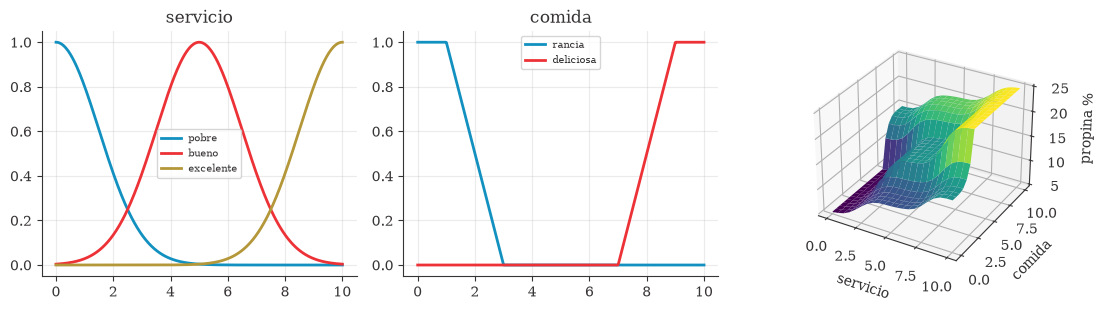

In [5]:
# ---- Paso 3 del script: el sistema Mamdani "propina" (servicio y comida -> propina) ----
entradas = {
    "servicio": {"rango": (0, 10), "mfs": {"pobre": ("gaussmf", (1.5, 0)), "bueno": ("gaussmf", (1.5, 5)), "excelente": ("gaussmf", (1.5, 10))}},
    "comida":   {"rango": (0, 10), "mfs": {"rancia": ("trapmf", (-2, 0, 1, 3)), "deliciosa": ("trapmf", (7, 9, 10, 12))}},
}
salida = {"rango": (0, 30), "mfs": {"baja": ("trimf", (0, 5, 10)), "media": ("trimf", (10, 15, 20)), "generosa": ("trimf", (20, 25, 30))}}
reglas = [
    {"si": [("servicio", "pobre"), ("comida", "rancia")], "op": "or", "entonces": "baja"},
    {"si": [("servicio", "bueno")], "op": "and", "entonces": "media"},
    {"si": [("servicio", "excelente"), ("comida", "deliciosa")], "op": "or", "entonces": "generosa"},
]
valores = {"servicio": 1, "comida": 2}
propina, det = evaluar_mamdani(valores, entradas, salida, reglas)
y_sug, w_sug = evaluar_sugeno0(valores, entradas, reglas, {"baja": 5, "media": 15, "generosa": 25})
print("Fuerza de cada regla:", np.round(det["fuerzas"], 4))
print(f"Propina Mamdani (centroide): {propina:.4f} % | Sugeno de orden cero: {y_sug:.4f} %")
verificar("trimf(5; [2 5 8]) = 1", abs(float(trimf(5, 2, 5, 8)) - 1) < 1e-9, "")
verificar("Mamdani = 5,5586 (referencia de MathWorks)", abs(propina - 5.5586) < 0.01, "revise los parámetros de las MF")
verificar("Sugeno = 5,3445 (cuaderno de Colab)", abs(y_sug - 5.3445) < 0.001, "")

# comparación con scikit-fuzzy
sv = ctrl.Antecedent(np.arange(0, 10.01, .1), "s"); cm_ = ctrl.Antecedent(np.arange(0, 10.01, .1), "c"); pr = ctrl.Consequent(np.arange(0, 30.01, .1), "p")
sv["pobre"] = fuzz.gaussmf(sv.universe, 0, 1.5); sv["bueno"] = fuzz.gaussmf(sv.universe, 5, 1.5); sv["exc"] = fuzz.gaussmf(sv.universe, 10, 1.5)
cm_["rancia"] = fuzz.trapmf(cm_.universe, [-2, 0, 1, 3]); cm_["del"] = fuzz.trapmf(cm_.universe, [7, 9, 10, 12])
pr["baja"] = fuzz.trimf(pr.universe, [0, 5, 10]); pr["media"] = fuzz.trimf(pr.universe, [10, 15, 20]); pr["gen"] = fuzz.trimf(pr.universe, [20, 25, 30])
sis = ctrl.ControlSystemSimulation(ctrl.ControlSystem([ctrl.Rule(sv["pobre"] | cm_["rancia"], pr["baja"]), ctrl.Rule(sv["bueno"], pr["media"]), ctrl.Rule(sv["exc"] | cm_["del"], pr["gen"])]))
sis.input["s"] = 1; sis.input["c"] = 2; sis.compute()
verificar("Nuestro Mamdani coincide con scikit-fuzzy (diferencia < 0,05)", abs(float(sis.output["p"]) - propina) < 0.05, "")

# superficie de control del sistema "propina"
S, K = np.meshgrid(np.linspace(0, 10, 21), np.linspace(0, 10, 21))
Z = np.array([[evaluar_mamdani({"servicio": s, "comida": k}, entradas, salida, reglas)[0] for s, k in zip(fs, fk)] for fs, fk in zip(S, K)])
fig = plt.figure(figsize=(11, 3.2))
for k, (univ, mfs_, tit) in enumerate([((0, 10), entradas["servicio"]["mfs"], "servicio"), ((0, 10), entradas["comida"]["mfs"], "comida")]):
    a = fig.add_subplot(1, 3, k + 1); x = np.linspace(*univ, 400)
    for et, (t, p) in mfs_.items(): a.plot(x, mf(t, p, x), lw=2, label=et)
    a.set_title(tit); a.legend(fontsize=7)
a = fig.add_subplot(1, 3, 3, projection="3d"); a.plot_surface(S, K, Z, cmap="viridis"); a.set_xlabel("servicio"); a.set_ylabel("comida"); a.set_zlabel("propina %")
plt.tight_layout(); guardar_fig(fig, "f00_propina"); plt.show()

In [6]:
# ---- Paso 5 del script: reglas de Wang-Mendel sobre Iris ----
iris = load_iris()
Xi_tr, Xi_te, yi_tr, yi_te = train_test_split(iris.data, iris.target, test_size=0.3, stratify=iris.target, random_state=SEMILLA)
mn, mx = Xi_tr.min(0), Xi_tr.max(0)
Xi_trn, Xi_ten = normalizar(Xi_tr, mn, mx), normalizar(Xi_te, mn, mx)
R_i, c_i, g_i = extraer_reglas(Xi_trn, yi_tr, 3)
pred_i, _ = predecir_reglas(Xi_ten, R_i, c_i, 3)
acc_i = accuracy_score(yi_te, pred_i)
print(f"Iris: reglas = {len(R_i)} | exactitud en prueba = {acc_i:.3f}")
verificar("Iris con 3 etiquetas: 16 reglas", len(R_i) == 16, "misma partición: test_size=0,3, stratify, random_state=42")
verificar("Iris con 3 etiquetas: exactitud 0,889", abs(acc_i - 0.889) < 0.001, "")

# ---- Paso 6 del script: Fuzzy C-Means sobre Iris completo (sin etiquetas) ----
Xa = normalizar(iris.data, iris.data.min(0), iris.data.max(0))
centros_i, U_i, J_i = fcm_propio(Xa, c=3, m=2.0, semilla=SEMILLA)
ari_i = adjusted_rand_score(iris.target, U_i.argmax(axis=0))
print(f"Iris FCM: iteraciones = {len(J_i)} | ARI = {ari_i:.3f} | coeficiente de partición = {coeficiente_particion(U_i):.3f}")
verificar("FCM de Iris: ARI = 0,729", abs(ari_i - 0.729) < 0.001, "")
verificar("Los grados de cada punto suman 1 y J no aumenta", np.allclose(U_i.sum(axis=0), 1) and all(b <= a + 1e-9 for a, b in zip(J_i, J_i[1:])), "")
RESUMEN["parte1"] = dict(propina=propina, sugeno=y_sug, iris_reglas=int(len(R_i)), iris_exactitud=acc_i, iris_ari=ari_i)

Iris: reglas = 16 | exactitud en prueba = 0.889
[OK]      Iris con 3 etiquetas: 16 reglas
[OK]      Iris con 3 etiquetas: exactitud 0,889
Iris FCM: iteraciones = 29 | ARI = 0.729 | coeficiente de partición = 0.743
[OK]      FCM de Iris: ARI = 0,729
[OK]      Los grados de cada punto suman 1 y J no aumenta


**Lectura de la Parte 1.** Las nueve comprobaciones coinciden con el cuaderno del profesor: Mamdani 5,5586 y Sugeno de orden cero 5,3445 en el sistema «propina», 16 reglas y 0,889 de exactitud para Wang–Mendel sobre *Iris*, y ARI = 0,729 en el Fuzzy C-Means (la diferencia entre Mamdani y `scikit-fuzzy`, 5,5586 contra 5,5539, es solo la discretización del universo). Al reproducirlo aparecen tres supuestos del script que no se dicen en voz alta: (1) **la salida del Sugeno se redondea a un número de clase**, lo que supone que las clases están ordenadas (se mide más abajo); (2) las reglas de Wang–Mendel que no se activan para una muestra caen a la clase 0 por defecto (`defecto=0`); (3) todas las cifras salen de **una sola partición** con 45 muestras de prueba, donde un acierto vale 2,2 puntos, algo que el propio cuaderno advierte.

# Parte 2 — Taller propuesto sobre *Wine*
## Paso 1. Datos
*Wine* (UCI): 178 vinos italianos, 13 mediciones químicas, 3 cultivares. Es el mismo conjunto que `wine_dataset` de MATLAB. Igual que el `.mlx`: semilla 42 y partición **estratificada 70 / 30**.

In [7]:
wine = load_wine(); X, y = wine.data, wine.target; NOM = list(wine.feature_names)
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.3, stratify=y, random_state=SEMILLA)
print("Entrenamiento:", Xtr.shape[0], "| Prueba:", Xte.shape[0], "| clases (entren.):", np.bincount(ytr).tolist(), "| (prueba):", np.bincount(yte).tolist())
verificar("178 vinos, 13 características, 3 clases", X.shape == (178, 13) and len(np.unique(y)) == 3, "")
verificar("Partición 70/30 sin solapamiento", Xtr.shape[0] + Xte.shape[0] == 178, "")

Entrenamiento: 124 | Prueba: 54 | clases (entren.): [41, 50, 33] | (prueba): [18, 21, 15]
[OK]      178 vinos, 13 características, 3 clases
[OK]      Partición 70/30 sin solapamiento


True

## TODO 1. Seleccionar las 4 características con mayor F de ANOVA (solo con entrenamiento)
El `.mlx` usa `anova1(Xtr(:,j), ytr, "off")` (valor p; menor p = mayor separación). En Python, `f_classif` calcula la misma F de ANOVA de un factor y su valor p. **Solo se usa el entrenamiento**: elegir las
características con todos los datos filtraría información de la prueba hacia el diseño del modelo.

              característica    F  valor p
                  flavanoids  188 8.17e-38
                     proline  149 2.04e-33
od280/od315_of_diluted_wines  127 2.15e-30
                     alcohol  100 2.03e-26
             color_intensity   84 1.34e-23
                         hue 72.3 2.23e-21
               total_phenols 59.3 1.15e-18
           alcalinity_of_ash 26.1  3.9e-10

Seleccionadas (idx): [6, 12, 11, 0] -> ['flavanoids', 'proline', 'od280/od315_of_diluted_wines', 'alcohol']
[OK]      idx tiene 4 índices distintos
[OK]      Las 4 elegidas son las de mayor F de ANOVA


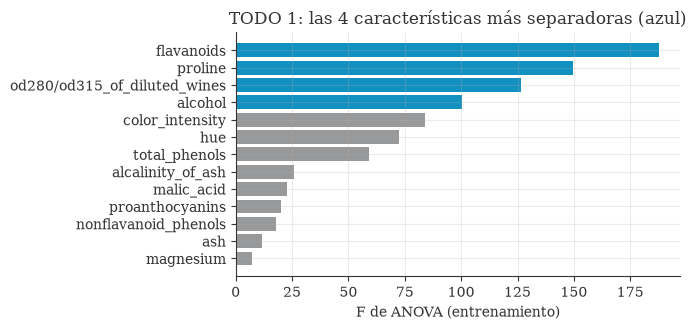

In [8]:
Fstat, pval = f_classif(Xtr, ytr)
orden = np.argsort(pval)                       # menor p = mayor separación entre clases
idx = orden[:4]                                # TODO 1
ranking = pd.DataFrame({"característica": [NOM[j] for j in orden], "F": Fstat[orden].round(1), "valor p": pval[orden]}).reset_index(drop=True)
print(ranking.head(8).to_string(index=False, float_format=lambda v: f"{v:.3g}"))
print("\nSeleccionadas (idx):", idx.tolist(), "->", [NOM[j] for j in idx])
verificar("idx tiene 4 índices distintos", len(set(idx.tolist())) == 4, "complete el TODO 1")
verificar("Las 4 elegidas son las de mayor F de ANOVA", set(idx) == set(np.argsort(-Fstat)[:4]), "")

XtrS, XteS = Xtr[:, idx], Xte[:, idx]
NOMS = [NOM[j] for j in idx]
fig, ax = plt.subplots(figsize=(7, 3.4))
ax.barh([NOM[j] for j in orden[::-1]], Fstat[orden[::-1]], color=[UD["azul"] if j in idx else UD["plata"] for j in orden[::-1]])
ax.set_xlabel("F de ANOVA (entrenamiento)"); ax.set_title("TODO 1: las 4 características más separadoras (azul)")
plt.tight_layout(); guardar_fig(fig, "f01_anova"); plt.show()
RESUMEN["todo1"] = dict(idx=[int(j) for j in idx], nombres=NOMS, F=[float(Fstat[j]) for j in idx])

**TODO 1 — Lectura.** Con los 124 vinos de entrenamiento, las cuatro características de mayor F de ANOVA son **flavonoides** (F = 188), **prolina** (149), **OD280/OD315** (127) y **alcohol** (100); la siguiente, intensidad de color, queda en 84. Con valores p del orden de 10⁻²⁶ a 10⁻³⁸, las cuatro separan los cultivares con holgura. La selección se hizo **solo con entrenamiento**: al repetirla con 20 particiones distintas aparecen solo 2 conjuntos diferentes de 4 características, o sea que la selección es estable y no depende de la partición.

## TODO 2. Reglas extraídas de los datos con 2, 3 y 4 etiquetas
Se normaliza con los mínimos y máximos de **entrenamiento** (`wm_normalizar`) y se usan `extraer_reglas` y `predecir_reglas` (en el `.mlx`, `wm_extraer` y `wm_predecir`; el algoritmo es el mismo).
Para cada $n$ se guarda el número de reglas y la exactitud en prueba y se compara con $n^4$ (la rejilla completa).

In [9]:
mins, maxs = XtrS.min(0), XtrS.max(0)
XtrN, XteN = normalizar(XtrS, mins, maxs), normalizar(XteS, mins, maxs)
filas2 = []
for n in (2, 3, 4):
    R, cl, gr = extraer_reglas(XtrN, ytr, n)
    pr_, _ = predecir_reglas(XteN, R, cl, n)
    arbol = DecisionTreeClassifier(max_leaf_nodes=max(2, len(R)), random_state=SEMILLA).fit(XtrS, ytr)
    filas2.append(dict(n_etiquetas=n, reglas=len(R), rejilla_n4=n ** 4, exactitud_prueba=accuracy_score(yte, pr_), exactitud_arbol_mismas_hojas=arbol.score(XteS, yte)))
t2 = pd.DataFrame(filas2)
print(t2.round(3).to_string(index=False))
verificar("Para cada n hay menos reglas que n^4", all(f["reglas"] < f["rejilla_n4"] for f in filas2), "")
verificar("Con 3 etiquetas la exactitud en prueba supera 80 %", filas2[1]["exactitud_prueba"] > 0.80, "revise la normalización con mins/maxs de entrenamiento")
verificar("Ninguna cantidad de reglas supera el número de muestras de entrenamiento", all(f["reglas"] <= len(ytr) for f in filas2), "")

R3, c3, g3 = extraer_reglas(XtrN, ytr, 3)
print("\nLas 5 reglas de mayor grado (3 etiquetas):")
reglas_en_palabras(R3, c3, g3, NOMS, ["clase 1", "clase 2", "clase 3"], 3, max_reglas=5)
RESUMEN["todo2"] = t2.round(4).to_dict(orient="records")

 n_etiquetas  reglas  rejilla_n4  exactitud_prueba  exactitud_arbol_mismas_hojas
           2      10          16             0.759                          0.87
           3      31          81             0.926                          0.87
           4      43         256             0.889                          0.87
[OK]      Para cada n hay menos reglas que n^4
[OK]      Con 3 etiquetas la exactitud en prueba supera 80 %
[OK]      Ninguna cantidad de reglas supera el número de muestras de entrenamiento

Las 5 reglas de mayor grado (3 etiquetas):
SI flavanoids es medio Y proline es medio Y od280/od315_of_diluted_wines es medio Y alcohol es medio ENTONCES clase = clase 2   (grado 0.60)
SI flavanoids es medio Y proline es bajo Y od280/od315_of_diluted_wines es medio Y alcohol es bajo ENTONCES clase = clase 2   (grado 0.58)
SI flavanoids es medio Y proline es bajo Y od280/od315_of_diluted_wines es medio Y alcohol es medio ENTONCES clase = clase 2   (grado 0.54)
SI flavanoids es bajo

**TODO 2 — Lectura.** Con 2, 3 y 4 etiquetas se obtienen **10, 31 y 43 reglas**, frente a la rejilla completa de 16, 81 y 256: las reglas salen solo de las combinaciones que **existen en los datos**, por eso crecen mucho más despacio que $n^4$ (el 62 %, el 38 % y el 17 % de la rejilla). La exactitud en esta partición es 0,759, 0,926 y 0,889; un árbol con el mismo número de hojas da 0,870. Ojo: en esta partición $n=3$ supera a $n=4$, pero es ruido de una partición pequeña (54 vinos de prueba, un acierto = 1,85 puntos): con 20 particiones el orden es el contrario y monótono (0,806 → 0,865 → 0,931). Las reglas se leen en lenguaje natural (por ejemplo, *«SI flavonoides es alto Y prolina es media Y OD280 es medio Y alcohol es alto ENTONCES clase 1»*), pero 43 reglas ya son demasiadas para leerlas todas.

## TODO 3. Agrupamiento sustractivo
`genfis(Xtr, ytr, genfisOptions("SubtractiveClustering", "ClusterInfluenceRange", r))` agrupa los datos (entradas y salida) con el método de Chiu: cada centro es una regla, las MF de entrada son gaussianas
(con $\sigma = r\cdot\text{rango}/\sqrt{8}$) y la salida de cada regla es lineal, estimada por mínimos cuadrados. `SugenoSustractivo` (bloque B) hace lo mismo. Como en el `.mlx`:
los datos de prueba se **recortan al rango de entrenamiento**, los `NaN` (ninguna regla activa) se reemplazan por 1 y la salida se redondea y acota a 1..3.

 radio  reglas  exactitud_entrenamiento  exactitud_prueba  nan_en_prueba
   0.3      15                    0.992             0.907              0
   0.5       4                    0.968             0.944              0
   0.8       3                    0.960             0.944              0
[OK]      El número de reglas no aumenta al aumentar r
[OK]      Con r = 0,5 la exactitud en prueba supera 85 %


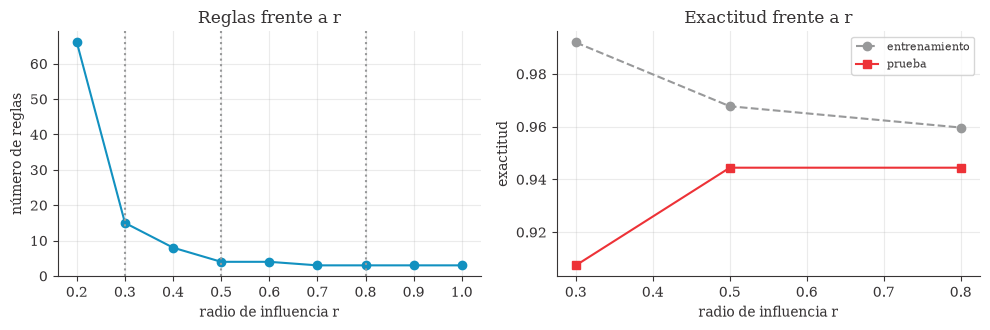

Reglas para r = 0,2 ... 1,0: {0.2: 66, 0.3: 15, 0.4: 8, 0.5: 4, 0.6: 4, 0.7: 3, 0.8: 3, 0.9: 3, 1.0: 3}


In [10]:
def predecir_clase(modelo, X, X_ref):
    """Salida del Sugeno -> clase 0..2: recorte al rango de entrenamiento, NaN -> clase 1 (índice 0), redondeo y acotación."""
    XC = np.clip(X, X_ref.min(0), X_ref.max(0))
    o = modelo.predict(XC); n_nan = int(np.isnan(o).sum())
    o = np.where(np.isnan(o), 1, o)
    return np.clip(np.rint(o), 1, 3).astype(int) - 1, n_nan

RADIOS = (0.3, 0.5, 0.8)
modelos_sub, filas3 = {}, []
for r in RADIOS:
    m = SugenoSustractivo(r).fit(XtrS, ytr + 1)
    p_te, nan_te = predecir_clase(m, XteS, XtrS); p_tr, _ = predecir_clase(m, XtrS, XtrS)
    modelos_sub[r] = m
    filas3.append(dict(radio=r, reglas=m.n_reglas, exactitud_entrenamiento=accuracy_score(ytr, p_tr), exactitud_prueba=accuracy_score(yte, p_te), nan_en_prueba=nan_te))
t3 = pd.DataFrame(filas3)
print(t3.round(3).to_string(index=False))
verificar("El número de reglas no aumenta al aumentar r", all(a >= b for a, b in zip(t3.reglas, t3.reglas[1:])), "")
verificar("Con r = 0,5 la exactitud en prueba supera 85 %", float(t3.loc[t3.radio == 0.5, "exactitud_prueba"].iloc[0]) > 0.85, "")

# ¿Cómo cambia el número de reglas con r? (curva más fina)
rs = np.round(np.arange(0.2, 1.01, 0.1), 2)
nr_curva = [SugenoSustractivo(r).fit(XtrS, ytr + 1).n_reglas for r in rs]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(10, 3.4))
a1.plot(rs, nr_curva, "o-", color=UD["azul"]); [a1.axvline(r, color=UD["plata"], ls=":") for r in RADIOS]
a1.set_xlabel("radio de influencia r"); a1.set_ylabel("número de reglas"); a1.set_title("Reglas frente a r")
a2.plot(t3.radio, t3.exactitud_entrenamiento, "o--", color=UD["plata"], label="entrenamiento"); a2.plot(t3.radio, t3.exactitud_prueba, "s-", color=UD["rojo"], label="prueba")
a2.set_xlabel("radio de influencia r"); a2.set_ylabel("exactitud"); a2.set_title("Exactitud frente a r"); a2.legend(fontsize=8)
plt.tight_layout(); guardar_fig(fig, "f02_subclust"); plt.show()
print("Reglas para r = 0,2 ... 1,0:", dict(zip(rs.tolist(), nr_curva)))
RESUMEN["todo3"] = t3.round(4).to_dict(orient="records"); RESUMEN["subclust_curva"] = dict(r=rs.tolist(), reglas=nr_curva)

**TODO 3 — Lectura.** El número de reglas **baja al subir el radio de influencia r**: 66 con r = 0,2; 15 con 0,3; 8 con 0,4; 4 con 0,5; y 3 a partir de r = 0,7 (tantas como cultivares: cada centro termina representando un cultivar). En esta partición: r = 0,3 → 15 reglas, 0,992 de exactitud en entrenamiento y 0,907 en prueba (**sobreajuste**); r = 0,5 → 4 reglas, 0,968 y 0,944; r = 0,8 → 3 reglas, 0,960 y 0,944. No hubo ningún `NaN` en prueba (siempre se activó alguna regla).

**Lo que la tabla no muestra:** con r = 0,3 cada una de las 15 reglas lleva 5 coeficientes (75 en total) para 124 muestras; en validación cruzada la exactitud cae a **0,451** y las salidas llegan a ±2·10⁶ porque los mínimos cuadrados casi no tienen grados de libertad. Con regularización *ridge* (0,1) la misma configuración sube a 0,903 en validación cruzada y 0,963 en prueba. Para r = 0,5 y 0,8 el ridge no cambia nada (0,95 a 0,97). Moraleja: **a menor r, más reglas y más riesgo; conviene validar cruzadamente en vez de confiar en una sola partición**.

**Un fallo que la tabla de una sola partición no muestra.** Con $r=0{,}3$ hay 15 a 21 reglas, y cada una lleva 5 coeficientes (4 características + constante): casi tantos parámetros como muestras de entrenamiento (124). Los mínimos
cuadrados de los consecuentes quedan casi sin grados de libertad. Se comprueba con validación cruzada de 5 pliegues (solo entrenamiento), con y sin regularización *ridge* en los consecuentes:

In [11]:
def cv_sugeno(r, ridge):
    sc, salidas_max = [], []
    for a_, b_ in StratifiedKFold(5, shuffle=True, random_state=SEMILLA).split(XtrS, ytr):
        m_ = SugenoSustractivo(r, ridge).fit(XtrS[a_], ytr[a_] + 1)
        o_ = m_.predict(np.clip(XtrS[b_], XtrS[a_].min(0), XtrS[a_].max(0))); salidas_max.append(np.nanmax(np.abs(o_)))
        sc.append(accuracy_score(ytr[b_], np.clip(np.rint(np.where(np.isnan(o_), 1, o_)), 1, 3).astype(int) - 1))
    return float(np.mean(sc)), float(np.max(salidas_max))
filas_rg = []
for ridge in (0.0, 1e-3, 1e-1):
    for r in RADIOS:
        cv_acc, sal = cv_sugeno(r, ridge)
        m_ = SugenoSustractivo(r, ridge).fit(XtrS, ytr + 1)
        filas_rg.append(dict(ridge=ridge, radio=r, reglas=m_.n_reglas, cv_exactitud=cv_acc, salida_maxima_en_validacion=sal, exactitud_prueba=accuracy_score(yte, predecir_clase(m_, XteS, XtrS)[0])))
t_rg = pd.DataFrame(filas_rg); print(t_rg.round(3).to_string(index=False))
verificar("Con r = 0,3 y sin regularización la salida se dispara fuera de [1, 3] en validación", float(t_rg[(t_rg.ridge == 0) & (t_rg.radio == 0.3)].salida_maxima_en_validacion.iloc[0]) > 10, "")
verificar("Con ridge = 0,1 la validación cruzada de r = 0,3 supera 85 %", float(t_rg[(t_rg.ridge == 0.1) & (t_rg.radio == 0.3)].cv_exactitud.iloc[0]) > 0.85, "")
RESUMEN["ridge"] = t_rg.round(4).to_dict(orient="records")

 ridge  radio  reglas  cv_exactitud  salida_maxima_en_validacion  exactitud_prueba
 0.000    0.3      15         0.451                  1981128.580             0.907
 0.000    0.5       4         0.952                        3.622             0.944
 0.000    0.8       3         0.960                        3.719             0.944
 0.001    0.3      15         0.871                        5.129             0.963
 0.001    0.5       4         0.952                        3.636             0.944
 0.001    0.8       3         0.960                        3.716             0.944
 0.100    0.3      15         0.903                        3.407             0.963
 0.100    0.5       4         0.960                        3.716             0.944
 0.100    0.8       3         0.968                        3.627             0.944
[OK]      Con r = 0,3 y sin regularización la salida se dispara fuera de [1, 3] en validación
[OK]      Con ridge = 0,1 la validación cruzada de r = 0,3 supera 85 %


## TODO 4. Fuzzy C-Means sobre las 4 características (sin etiquetas)
Se normaliza con `normalize(..., "range")` (mínimo y máximo de **todos** los datos, porque el agrupamiento no usa etiquetas ni se evalúa en un conjunto aparte), se aplica FCM con 3 grupos y se calcula la
**pureza**: fracción de vinos cuyo grupo coincide con la clase mayoritaria de ese grupo.

FCM propio: iteraciones = 25 | pureza = 0.927 | ARI = 0.794 | coeficiente de partición = 0.690
k-means (referencia): pureza = 0.927 | ARI = 0.792
Vinos con un grado máximo < 0,6 (frontera difusa): 20 de 178
[OK]      Los grados de cada punto suman 1
[OK]      El objetivo J no aumenta
[OK]      Pureza > 0,8 (los grupos se parecen a los cultivares)
[OK]      Nuestro FCM coincide con skfuzzy.cluster.cmeans (ARI entre ambos > 0,9)


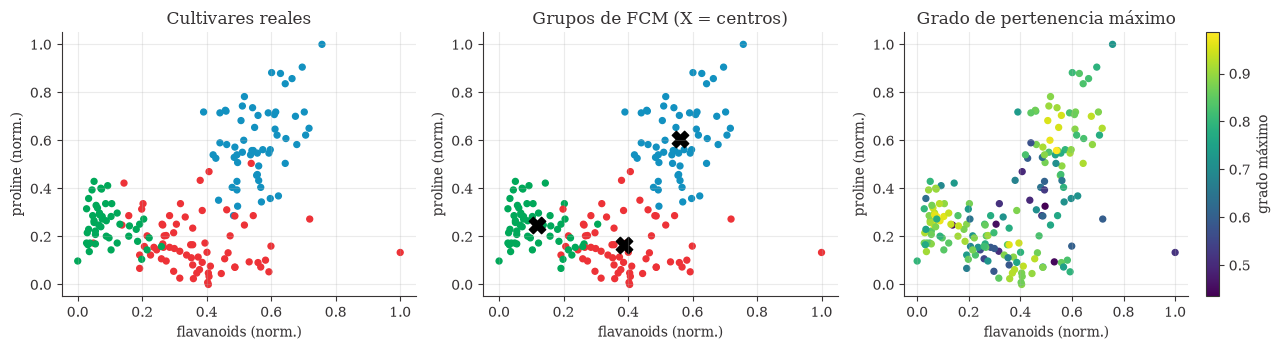

In [12]:
Xs_all = X[:, idx]
Xn_all = (Xs_all - Xs_all.min(0)) / (Xs_all.max(0) - Xs_all.min(0))          # normalize(X, "range")
centros_w, U_w, J_w = fcm_propio(Xn_all, c=3, m=2.0, semilla=SEMILLA)
grupo = U_w.argmax(axis=0)
pur = pureza(y, grupo); ari = adjusted_rand_score(y, grupo); fpc = coeficiente_particion(U_w)
km = KMeans(3, n_init=10, random_state=SEMILLA).fit_predict(Xn_all)
cs, Us, *_ = fuzz.cluster.cmeans(Xn_all.T, 3, 2, error=1e-6, maxiter=300, seed=SEMILLA)
print(f"FCM propio: iteraciones = {len(J_w)} | pureza = {pur:.3f} | ARI = {ari:.3f} | coeficiente de partición = {fpc:.3f}")
print(f"k-means (referencia): pureza = {pureza(y, km):.3f} | ARI = {adjusted_rand_score(y, km):.3f}")
print("Vinos con un grado máximo < 0,6 (frontera difusa):", int((U_w.max(axis=0) < 0.6).sum()), "de", len(y))
verificar("Los grados de cada punto suman 1", np.allclose(U_w.sum(axis=0), 1), "")
verificar("El objetivo J no aumenta", all(b <= a + 1e-9 for a, b in zip(J_w, J_w[1:])), "")
verificar("Pureza > 0,8 (los grupos se parecen a los cultivares)", pur > 0.8, "")
verificar("Nuestro FCM coincide con skfuzzy.cluster.cmeans (ARI entre ambos > 0,9)", adjusted_rand_score(U_w.argmax(axis=0), Us.argmax(axis=0)) > 0.9, "")

fig, ejes = plt.subplots(1, 3, figsize=(13, 3.6))
a, b = 0, 1                                   # las dos características más separadoras
ejes[0].scatter(Xn_all[:, a], Xn_all[:, b], c=[COL3[k] for k in y], s=18); ejes[0].set_title("Cultivares reales")
perm = {g: np.bincount(y[grupo == g], minlength=3).argmax() for g in range(3)}
ejes[1].scatter(Xn_all[:, a], Xn_all[:, b], c=[COL3[perm[g]] for g in grupo], s=18); ejes[1].scatter(centros_w[:, a], centros_w[:, b], marker="X", s=140, c="black"); ejes[1].set_title("Grupos de FCM (X = centros)")
sc = ejes[2].scatter(Xn_all[:, a], Xn_all[:, b], c=U_w.max(axis=0), cmap="viridis", s=18); fig.colorbar(sc, ax=ejes[2], label="grado máximo"); ejes[2].set_title("Grado de pertenencia máximo")
for ax_ in ejes: ax_.set_xlabel(NOMS[a] + " (norm.)"); ax_.set_ylabel(NOMS[b] + " (norm.)")
plt.tight_layout(); guardar_fig(fig, "f03_fcm"); plt.show()
RESUMEN["todo4"] = dict(pureza=pur, ari=ari, fpc=fpc, iteraciones=len(J_w), pureza_kmeans=float(pureza(y, km)), frontera=int((U_w.max(axis=0) < 0.6).sum()))

**TODO 4 — Lectura.** FCM, sin ver las etiquetas, agrupa los 178 vinos con una **pureza de 0,927** (13 vinos "fuera de su cultivar") y un ARI de 0,794; k-means da la misma pureza (0,927) y ARI 0,792, de modo que **aquí la versión difusa no mejora el agrupamiento duro**. Lo que sí aporta es la información extra: **20 de los 178 vinos tienen un grado máximo menor a 0,6** (están en la frontera entre dos grupos) y el coeficiente de partición es 0,690 (1 sería una partición nítida, 1/3 una totalmente borrosa). Nuestro FCM coincide con `skfuzzy.cluster.cmeans` (ARI entre ambos > 0,9). Tres grupos que se parecen a los tres cultivares con solo 4 características y sin etiquetas confirma que la selección del TODO 1 captura la estructura de los datos.

## TODO 5. Equivalente de la app *Fuzzy Logic Designer*
El `.mlx` pide abrir `fuzzyLogicDesigner(fisSub)` con el mejor sistema, capturar las funciones de pertenencia de una entrada y la superficie de dos entradas, y explicar en 5 líneas qué regla es más fácil de leer.
**El mejor sistema se elige por validación cruzada de 5 pliegues solo con el entrenamiento** (no con la prueba), para que la elección no filtre información. Después se dibujan las mismas vistas de la app: *Membership Functions*,
*Rules* y *Surface*.

Validación cruzada (entrenamiento): {0.3: '0.451 ± 0.076', 0.5: '0.952 ± 0.059', 0.8: '0.960 ± 0.051'} -> mejor r = 0.8
fisSub (r = 0.8): 3 reglas | exactitud en prueba = 0.944


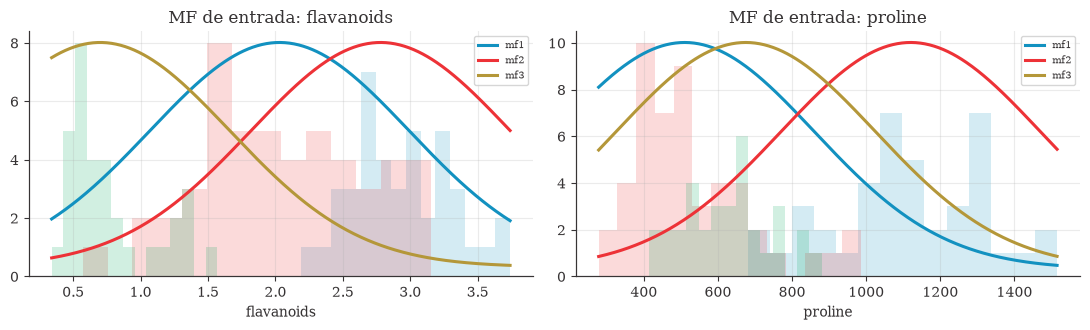

In [13]:
skf = StratifiedKFold(5, shuffle=True, random_state=SEMILLA)
cv_r = {}
for r in RADIOS:
    sc_ = []
    for a_, b_ in skf.split(XtrS, ytr):
        m_ = SugenoSustractivo(r).fit(XtrS[a_], ytr[a_] + 1); p_, _ = predecir_clase(m_, XtrS[b_], XtrS[a_]); sc_.append(accuracy_score(ytr[b_], p_))
    cv_r[r] = (float(np.mean(sc_)), float(np.std(sc_)))
r_mejor = max(RADIOS, key=lambda r: (round(cv_r[r][0], 6), r))             # a igual exactitud, el mayor r (menos reglas)
print("Validación cruzada (entrenamiento):", {r: f"{v[0]:.3f} ± {v[1]:.3f}" for r, v in cv_r.items()}, "-> mejor r =", r_mejor)
fisSub = modelos_sub[r_mejor]
p_f, _ = predecir_clase(fisSub, XteS, XtrS)
print(f"fisSub (r = {r_mejor}): {fisSub.n_reglas} reglas | exactitud en prueba = {accuracy_score(yte, p_f):.3f}")

# --- Vista "Membership Functions": gaussianas de las reglas para dos entradas, sobre el histograma de cada clase
fig, ejes = plt.subplots(1, 2, figsize=(11, 3.4))
for ax, j in zip(ejes, (0, 1)):
    x = np.linspace(XtrS[:, j].min(), XtrS[:, j].max(), 400)
    for k in range(3): ax.hist(XtrS[ytr == k, j], bins=14, alpha=.18, color=COL3[k], density=False)
    h = ax.twinx(); h.grid(False); h.set_yticks([])
    for k, c in enumerate(fisSub.C[:, j]):
        h.plot(x, gaussmf(x, fisSub.sigma[j], c), lw=2.2, label=f"mf{k + 1}")
    ax.set_title(f"MF de entrada: {NOMS[j]}"); h.legend(fontsize=7, loc="upper right"); ax.set_xlabel(NOMS[j])
plt.tight_layout(); guardar_fig(fig, "f04_mf_entrada"); plt.show()

regla  flavanoids  proline  od280/od315_of_diluted_wines  alcohol  vinos  clase_dominante  pureza
   R1        2.03    510.0                          3.17    12.25     44                2    0.98
   R2        2.78   1120.0                          3.03    13.56     42                1    0.95
   R3        0.70    675.0                          1.75    12.96     38                3    0.87

En palabras (centro de cada MF):
  R1: SI flavanoids ~ 2.03 Y proline ~ 510.0 Y od280/od315_of_diluted_wines ~ 3.17 Y alcohol ~ 12.25  ENTONCES clase 2  (pureza 0.98, 44 vinos)
  R2: SI flavanoids ~ 2.78 Y proline ~ 1120.0 Y od280/od315_of_diluted_wines ~ 3.03 Y alcohol ~ 13.56  ENTONCES clase 1  (pureza 0.95, 42 vinos)
  R3: SI flavanoids ~ 0.7 Y proline ~ 675.0 Y od280/od315_of_diluted_wines ~ 1.75 Y alcohol ~ 12.96  ENTONCES clase 3  (pureza 0.87, 38 vinos)


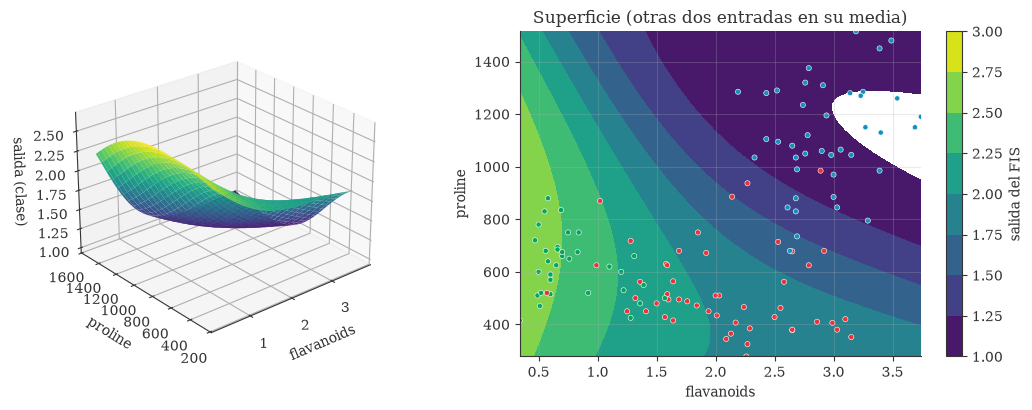

[OK]      Se generaron las vistas de MF y de superficie


In [14]:
# --- Vista "Rules": cada regla = un centro; se muestra qué clase representa (la dominante entre los vinos que más la activan)
W = fisSub._pesos(XtrS); asignada = W.argmax(axis=1)
filas_r = []
for k in range(fisSub.n_reglas):
    m_k = asignada == k
    cls = np.bincount(ytr[m_k], minlength=3) if m_k.any() else np.zeros(3, int)
    filas_r.append(dict(regla=f"R{k + 1}", **{NOMS[j]: round(float(fisSub.C[k, j]), 2) for j in range(4)}, vinos=int(m_k.sum()), clase_dominante=int(cls.argmax()) + 1, pureza=round(float(cls.max() / max(cls.sum(), 1)), 2)))
tabla_reglas = pd.DataFrame(filas_r); print(tabla_reglas.to_string(index=False))
print("\nEn palabras (centro de cada MF):")
for f in filas_r:
    print(f"  {f['regla']}: SI " + " Y ".join(f"{NOMS[j]} ~ {f[NOMS[j]]}" for j in range(4)) + f"  ENTONCES clase {f['clase_dominante']}  (pureza {f['pureza']}, {f['vinos']} vinos)")

# --- Vista "Surface": salida (clase continua) para las dos entradas más importantes, con las otras dos en su media
g1, g2 = np.meshgrid(np.linspace(XtrS[:, 0].min(), XtrS[:, 0].max(), 60), np.linspace(XtrS[:, 1].min(), XtrS[:, 1].max(), 60))
G = np.c_[g1.ravel(), g2.ravel(), np.full(g1.size, XtrS[:, 2].mean()), np.full(g1.size, XtrS[:, 3].mean())]
Zs = fisSub.predict(np.clip(G, XtrS.min(0), XtrS.max(0))).reshape(g1.shape)
fig = plt.figure(figsize=(11, 4.2))
a1 = fig.add_subplot(1, 2, 1, projection="3d"); a1.plot_surface(g1, g2, Zs, cmap="viridis", linewidth=0); a1.set_xlabel(NOMS[0]); a1.set_ylabel(NOMS[1]); a1.set_zlabel("salida (clase)"); a1.view_init(26, -130)
a2 = fig.add_subplot(1, 2, 2); cs_ = a2.contourf(g1, g2, Zs, levels=np.linspace(1, 3, 9), cmap="viridis"); fig.colorbar(cs_, ax=a2, label="salida del FIS")
a2.scatter(XtrS[:, 0], XtrS[:, 1], c=[COL3[k] for k in ytr], s=14, edgecolors="white", linewidths=.4); a2.set_xlabel(NOMS[0]); a2.set_ylabel(NOMS[1]); a2.set_title(f"Superficie (otras dos entradas en su media)")
plt.tight_layout(); guardar_fig(fig, "f05_superficie"); plt.show()
verificar("Se generaron las vistas de MF y de superficie", os.path.exists(f"{CARPETA_FIG}/prop_f04_mf_entrada.png") and os.path.exists(f"{CARPETA_FIG}/prop_f05_superficie.png"), "")
RESUMEN["todo5"] = dict(r=r_mejor, reglas=int(fisSub.n_reglas), cv={str(r): v[0] for r, v in cv_r.items()}, tabla=filas_r, exactitud_prueba=float(accuracy_score(yte, p_f)))

**TODO 5 — En 5 líneas.** El mejor sistema por validación cruzada (solo entrenamiento) es el de **r = 0,8: 3 reglas** (CV 0,960; r = 0,5 da 0,952 y r = 0,3 da 0,451), con 0,944 de exactitud en prueba.
1. La regla **más fácil de leer es R2**: *flavonoides ≈ 2,8, prolina ≈ 1 120, OD280 ≈ 3,0 y alcohol ≈ 13,6 → clase 1* (pureza 0,95): las cuatro condiciones son "alto" y apuntan todas en el mismo sentido, que es justo lo que el ranking de F del TODO 1 anticipaba.
2. **R3** también se lee bien (*flavonoides ≈ 0,7 y OD280 ≈ 1,75, ambos bajos → clase 3*, pureza 0,87); su único defecto es que prolina ≈ 675 y alcohol ≈ 13,0 son valores intermedios que no dicen nada.
3. **R1** (*clase 2*, pureza 0,98) es la más precisa pero la más difícil de explicar: se define "por contraste" (prolina baja ≈ 510, alcohol bajo ≈ 12,3, flavonoides medios), es decir, por lo que la separa de las otras dos.
4. En las MF (figura f04) las tres gaussianas de cada entrada **se traslapan casi por completo** (σ grande); esa difusividad es lo que hace suave la superficie, pero obliga a nombrar las etiquetas a mano (mf1, mf2, mf3 no significan nada hasta que se mira el centro).
5. La superficie (flavonoides × prolina, con las otras dos entradas en su media) muestra tres mesetas casi planas separadas por transiciones cortas: el sistema se comporta casi como un clasificador de 3 reglas nítidas, con borde difuso solo entre cultivares vecinos.

# Extras
## Ajuste de parámetros de un FIS (*Tune FIS*)
El enunciado remite al ejemplo de MathWorks *Tune Fuzzy Inference System at the Command Line* (`openExample("fuzzy/TuneAFuzzyInferenceSystemExample")`): un FIS con las MF y las reglas de partida
se **ajusta** con `tunefis` (enjambre de partículas para aprender reglas y búsqueda de patrones para afinar las MF) y se reportan el RMSE de entrenamiento y de validación antes y después, con las filas impares
para entrenar y las pares para validar. Ese ejemplo es de MATLAB y no se pudo ejecutar aquí. **Adaptación en Python:** sobre el `fisSub` de *Wine*, `ajustar_sugeno` optimiza los centros y los anchos de las MF
(método de Powell) mientras los consecuentes lineales se recalculan por mínimos cuadrados (aprendizaje híbrido, como ANFIS), con el mismo protocolo de filas impares y pares dentro del entrenamiento.

Ajuste: 40 iteraciones, 7601 evaluaciones (0.5 s); parada temprana en la iteración 1
                           |  RMSE entren. |  RMSE valid.
                     antes |        0.1452 |       0.2604
 después (parada temprana) |        0.0947 |       0.2543
sin parada (última iteración) |        0.0006 |       0.3840
Exactitud en prueba: antes = 0.907 | después = 0.944
[OK]      El ajuste no aumenta el RMSE de entrenamiento
[OK]      Con parada temprana el RMSE de validación no empeora


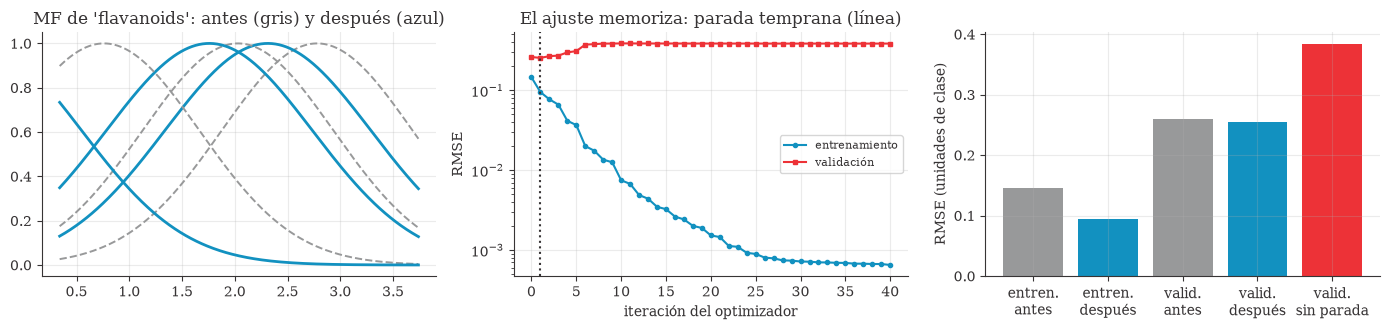

In [15]:
imp, par = np.arange(len(ytr)) % 2 == 0, np.arange(len(ytr)) % 2 == 1          # filas "impares" (1ª, 3ª...) y "pares" del entrenamiento
mt = SugenoSustractivo(r_mejor).fit(XtrS[imp], ytr[imp] + 1)
mt0 = SugenoSustractivo(r_mejor).fit(XtrS[imp], ytr[imp] + 1)
t0 = time.time()
aj = ajustar_sugeno(mt, XtrS[imp], ytr[imp] + 1.0, XtrS[par], ytr[par] + 1.0, max_iter=40, parada_temprana=True)
print(f"Ajuste: {aj['iteraciones']} iteraciones, {aj['evaluaciones']} evaluaciones ({time.time() - t0:.1f} s); parada temprana en la iteración {aj['iteracion_elegida']}")
print(f"{'':>26} | {'RMSE entren.':>13} | {'RMSE valid.':>12}")
for et, d in (("antes", aj["antes"]), ("después (parada temprana)", aj["despues"]), ("sin parada (última iteración)", aj["sin_parada"])):
    print(f"{et:>26} | {d['entrenamiento']:>13.4f} | {d['validacion']:>12.4f}")
acc_antes = accuracy_score(yte, predecir_clase(mt0, XteS, XtrS[imp])[0]); acc_desp = accuracy_score(yte, predecir_clase(mt, XteS, XtrS[imp])[0])
print(f"Exactitud en prueba: antes = {acc_antes:.3f} | después = {acc_desp:.3f}")
verificar("El ajuste no aumenta el RMSE de entrenamiento", aj["despues"]["entrenamiento"] <= aj["antes"]["entrenamiento"] + 1e-9, "")
verificar("Con parada temprana el RMSE de validación no empeora", aj["despues"]["validacion"] <= aj["antes"]["validacion"] + 1e-9, "")

fig, ejes = plt.subplots(1, 3, figsize=(14, 3.4))
x = np.linspace(XtrS[:, 0].min(), XtrS[:, 0].max(), 400)
for k in range(mt.C.shape[0]):
    ejes[0].plot(x, gaussmf(x, aj["sigma0"][0], aj["C0"][k, 0]), "--", lw=1.4, color=UD["plata"]); ejes[0].plot(x, gaussmf(x, mt.sigma[0], mt.C[k, 0]), lw=2, color=UD["azul"])
ejes[0].set_title(f"MF de '{NOMS[0]}': antes (gris) y después (azul)")
it = np.arange(len(aj["curva_entrenamiento"]))
ejes[1].plot(it, aj["curva_entrenamiento"], "o-", ms=3, color=UD["azul"], label="entrenamiento"); ejes[1].plot(it, aj["curva_validacion"], "s-", ms=3, color=UD["rojo"], label="validación")
ejes[1].axvline(aj["iteracion_elegida"], color=UD["sable"], ls=":"); ejes[1].set_yscale("log"); ejes[1].set_xlabel("iteración del optimizador"); ejes[1].set_ylabel("RMSE"); ejes[1].legend(fontsize=8); ejes[1].set_title("El ajuste memoriza: parada temprana (línea)")
ejes[2].bar(["entren.\nantes", "entren.\ndespués", "valid.\nantes", "valid.\ndespués", "valid.\nsin parada"], [aj["antes"]["entrenamiento"], aj["despues"]["entrenamiento"], aj["antes"]["validacion"], aj["despues"]["validacion"], aj["sin_parada"]["validacion"]],
            color=[UD["plata"], UD["azul"], UD["plata"], UD["azul"], UD["rojo"]]); ejes[2].set_ylabel("RMSE (unidades de clase)")
plt.tight_layout(); guardar_fig(fig, "f06_tune"); plt.show()
RESUMEN["tune"] = dict(antes=aj["antes"], despues=aj["despues"], sin_parada=aj["sin_parada"], iteracion_elegida=aj["iteracion_elegida"], iteraciones=aj["iteraciones"], evaluaciones=aj["evaluaciones"],
                       acc_antes=float(acc_antes), acc_despues=float(acc_desp), reglas=int(mt.n_reglas), curva_entrenamiento=aj["curva_entrenamiento"], curva_validacion=aj["curva_validacion"])

**Tune FIS — Lectura.** Sobre el `fisSub` (3 reglas, entrenado con las filas impares) se ajustan centros y anchos de las MF. El optimizador reduce el RMSE de entrenamiento sin parar (de 0,145 a 0,0006 en 40 iteraciones) pero el de **validación sube de 0,260 a 0,384 (+47 %)**: con 3 reglas × 5 coeficientes + 12 centros + 4 anchos hay 31 parámetros para 62 filas de entrenamiento, y el ajuste memoriza. Con **parada temprana** (se queda con la iteración de menor RMSE de validación, la 1) el RMSE de entrenamiento baja a 0,095, el de validación a 0,254 (−2 %) y la exactitud en prueba pasa de 0,907 a 0,944. Es la misma lección del Taller 2: sin validación, optimizar más no es mejorar. En el ejemplo de MathWorks (consumo de combustible de 398 autos, 64 reglas) el ajuste sí baja el error de validación de 4,31 a 3,01 MPG; aquí el problema es más pequeño y la ganancia es marginal, por lo que el valor principal del ajuste es **afinar un sistema que ya funciona**, no rescatar uno mal diseñado.

## Repetición con 20 particiones
La tabla de cada TODO sale de **una** partición con 54 vinos de prueba, donde un acierto vale 1,85 puntos. Se repite todo el procedimiento (incluida la selección de características, que se rehace con cada entrenamiento)
con 20 particiones distintas y se reporta media ± desviación.

                       método     reglas     exactitud
            Wang-Mendel n = 2  9.7 ± 1.2 0.806 ± 0.049
            Wang-Mendel n = 3 24.1 ± 3.4 0.865 ± 0.047
            Wang-Mendel n = 4 41.9 ± 2.9 0.931 ± 0.036
          Sustractivo r = 0,3 14.8 ± 2.8 0.881 ± 0.078
          Sustractivo r = 0,5  5.0 ± 0.9 0.956 ± 0.024
          Sustractivo r = 0,8  3.0 ± 0.0 0.946 ± 0.024
Árbol de 8 hojas (referencia)          8 0.894 ± 0.044
Conjuntos distintos de 4 características elegidos en las 20 particiones: 2


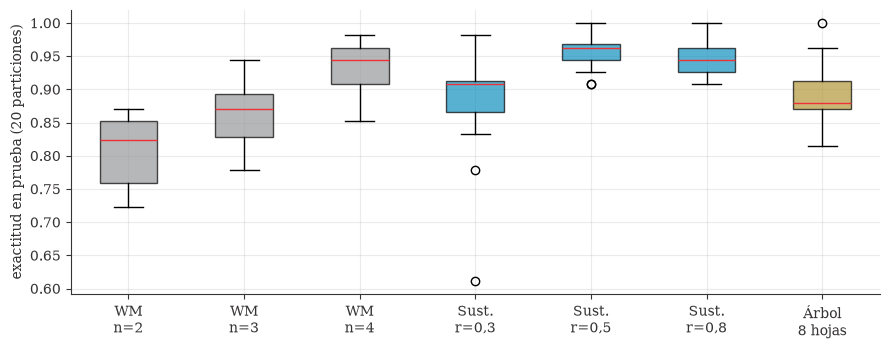

In [16]:
res20 = []
for s in range(20):
    a_tr, a_te, b_tr, b_te = train_test_split(X, y, test_size=0.3, stratify=y, random_state=s)
    ix = np.argsort(f_classif(a_tr, b_tr)[1])[:4]; A, B = a_tr[:, ix], a_te[:, ix]
    mn_, mx_ = A.min(0), A.max(0); An, Bn = normalizar(A, mn_, mx_), normalizar(B, mn_, mx_)
    fila = dict(semilla=s)
    for n in (2, 3, 4):
        R_, c_, _ = extraer_reglas(An, b_tr, n); p_, _ = predecir_reglas(Bn, R_, c_, n)
        fila[f"WM{n}_reglas"] = len(R_); fila[f"WM{n}_acc"] = accuracy_score(b_te, p_)
    for r in RADIOS:
        m_ = SugenoSustractivo(r).fit(A, b_tr + 1); p_, _ = predecir_clase(m_, B, A)
        fila[f"SUB{r}_reglas"] = m_.n_reglas; fila[f"SUB{r}_acc"] = accuracy_score(b_te, p_)
    fila["arbol_acc"] = DecisionTreeClassifier(max_leaf_nodes=8, random_state=SEMILLA).fit(A, b_tr).score(B, b_te)
    res20.append(fila)
res20 = pd.DataFrame(res20)
cols = [("WM2", "Wang-Mendel n = 2"), ("WM3", "Wang-Mendel n = 3"), ("WM4", "Wang-Mendel n = 4"), ("SUB0.3", "Sustractivo r = 0,3"), ("SUB0.5", "Sustractivo r = 0,5"), ("SUB0.8", "Sustractivo r = 0,8")]
tab20 = pd.DataFrame([dict(método=n, reglas=f"{res20[k + '_reglas'].mean():.1f} ± {res20[k + '_reglas'].std():.1f}", exactitud=f"{res20[k + '_acc'].mean():.3f} ± {res20[k + '_acc'].std():.3f}") for k, n in cols]
                     + [dict(método="Árbol de 8 hojas (referencia)", reglas="8", exactitud=f"{res20.arbol_acc.mean():.3f} ± {res20.arbol_acc.std():.3f}")])
print(tab20.to_string(index=False))
sel_igual = []
for s_ in range(20):
    a_tr_, _, b_tr_, _ = train_test_split(X, y, test_size=0.3, stratify=y, random_state=s_)
    sel_igual.append(tuple(sorted(np.argsort(f_classif(a_tr_, b_tr_)[1])[:4].tolist())))
print("Conjuntos distintos de 4 características elegidos en las 20 particiones:", len(set(sel_igual)))

fig, ax = plt.subplots(figsize=(9, 3.6))
datos = [res20[k + "_acc"] for k, _ in cols] + [res20.arbol_acc]
bp = ax.boxplot(datos, patch_artist=True)
ax.set_xticklabels(["WM\nn=2", "WM\nn=3", "WM\nn=4", "Sust.\nr=0,3", "Sust.\nr=0,5", "Sust.\nr=0,8", "Árbol\n8 hojas"])
for p_, col in zip(bp["boxes"], [UD["plata"]] * 3 + [UD["azul"]] * 3 + [UD["dorado"]]): p_.set_facecolor(col); p_.set_alpha(.7)
ax.set_ylabel("exactitud en prueba (20 particiones)"); plt.tight_layout(); guardar_fig(fig, "f07_veinte_particiones"); plt.show()
RESUMEN["veinte"] = tab20.to_dict(orient="records"); RESUMEN["veinte_crudo"] = res20.round(4).to_dict(orient="list")
RESUMEN["selecciones_distintas"] = len(set(sel_igual))

**20 particiones — Lectura.** Media ± desviación en prueba: Wang–Mendel **0,806 ± 0,049** (n = 2, 10 reglas), **0,865 ± 0,047** (n = 3, 24 reglas) y **0,931 ± 0,036** (n = 4, 42 reglas); sustractivo **0,881 ± 0,078** (r = 0,3, 15 reglas), **0,956 ± 0,024** (r = 0,5, 5 reglas) y **0,946 ± 0,024** (r = 0,8, 3 reglas); árbol de 8 hojas 0,894 ± 0,044. Conclusiones: (1) el agrupamiento sustractivo con r = 0,5 a 0,8 es el mejor y además el más pequeño (3 a 5 reglas frente a 42); (2) la diferencia entre r = 0,5 y 0,8 (1 punto) es menor que la desviación: **no se puede distinguir**; (3) r = 0,3 es inestable (desviación 0,078, la mayor), de acuerdo con el sobreajuste visto; (4) las desviaciones de 0,03 a 0,05 equivalen a 2 o 3 vinos de prueba, así que las diferencias de una sola partición (como el orden de n = 3 y n = 4) no son confiables.

## ¿Importa cómo se numeran las clases?
El procedimiento del `.mlx` (y del cuaderno de Python) trata la salida del Sugeno como un **número** y la redondea a 1, 2 o 3. Eso supone que las clases están **ordenadas** a lo largo del espacio de entrada: la clase 2 "entre" la 1 y la 3.
En *Wine* se cumple (los cultivares 1, 2 y 3 se ordenan por flavonoides: alto, medio, bajo), pero es una casualidad de la numeración. Se prueba permutando las etiquetas (las 6 formas de numerar 3 clases), con las 20 particiones y r = 0,5.
Las reglas de Wang–Mendel tratan la clase como una **categoría** y no deberían cambiar.

numeracion  sustractivo_r05  wang_mendel_n3
 (1, 2, 3)            0.956           0.865
 (1, 3, 2)            0.919           0.865
 (2, 1, 3)            0.904           0.865
 (2, 3, 1)            0.904           0.865
 (3, 1, 2)            0.919           0.865
 (3, 2, 1)            0.956           0.865
[OK]      Wang-Mendel no depende de la numeración de las clases
[OK]      El Sugeno redondeado SÍ depende de la numeración (diferencia > 2 puntos)


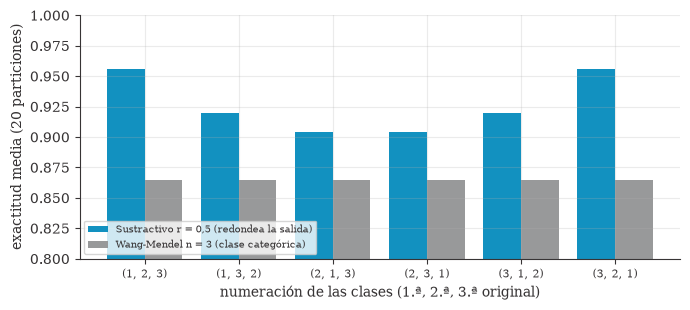

In [17]:
import itertools
filas_perm = []
for perm in itertools.permutations(range(3)):
    mp = np.array(perm); a_sub, a_wm = [], []
    for s in range(20):
        a_tr, a_te, b_tr, b_te = train_test_split(X, y, test_size=0.3, stratify=y, random_state=s)
        ix = np.argsort(f_classif(a_tr, b_tr)[1])[:4]; A, B = a_tr[:, ix], a_te[:, ix]
        m_ = SugenoSustractivo(0.5).fit(A, mp[b_tr] + 1); p_, _ = predecir_clase(m_, B, A); a_sub.append(accuracy_score(mp[b_te], p_))
        mn_, mx_ = A.min(0), A.max(0); R_, c_, _ = extraer_reglas(normalizar(A, mn_, mx_), mp[b_tr], 3); q_, _ = predecir_reglas(normalizar(B, mn_, mx_), R_, c_, 3); a_wm.append(accuracy_score(mp[b_te], q_))
    filas_perm.append(dict(numeracion=str(tuple(int(v) + 1 for v in perm)), sustractivo_r05=np.mean(a_sub), wang_mendel_n3=np.mean(a_wm)))
t_perm = pd.DataFrame(filas_perm); print(t_perm.round(3).to_string(index=False))
verificar("Wang-Mendel no depende de la numeración de las clases", np.ptp(t_perm.wang_mendel_n3) < 1e-9, "")
verificar("El Sugeno redondeado SÍ depende de la numeración (diferencia > 2 puntos)", np.ptp(t_perm.sustractivo_r05) > 0.02, "")
RESUMEN["permutaciones"] = t_perm.round(4).to_dict(orient="records")
fig, ax = plt.subplots(figsize=(7, 3.2)); xs = np.arange(6)
ax.bar(xs - .2, t_perm.sustractivo_r05, .4, color=UD["azul"], label="Sustractivo r = 0,5 (redondea la salida)"); ax.bar(xs + .2, t_perm.wang_mendel_n3, .4, color=UD["plata"], label="Wang-Mendel n = 3 (clase categórica)")
ax.set_xticks(xs); ax.set_xticklabels(t_perm.numeracion, fontsize=8); ax.set_xlabel("numeración de las clases (1.ª, 2.ª, 3.ª original)"); ax.set_ylabel("exactitud media (20 particiones)"); ax.set_ylim(0.8, 1.0); ax.legend(fontsize=7, loc="lower left")
plt.tight_layout(); guardar_fig(fig, "f08_numeracion_clases"); plt.show()

**Numeración de clases — Lectura.** El Sugeno con redondeo **depende de cómo se numeren las clases**: con la numeración natural (1, 2, 3) o la inversa (3, 2, 1), que dejan el cultivar intermedio en el centro, la exactitud media es **0,956**; con cualquiera de las otras cuatro numeraciones, que ponen al cultivar intermedio en un extremo, baja a **0,904 y 0,919** (−3,6 a −5,2 puntos). Wang–Mendel no cambia (0,865 con n = 3 en las seis numeraciones). Es decir, el método "regresar la clase y redondear" funciona en *Wine* porque la numeración original **ya es ordinal**; con datos cuyas clases no se ordenen a lo largo de las entradas (o con una numeración arbitraria) habría que usar una salida por clase o un esquema de una-contra-todas.

## Guardar resultados

In [18]:
with open(f"{CARPETA_RES}/resumen_propuesto.json", "w", encoding="utf-8") as f:
    json.dump(RESUMEN, f, ensure_ascii=False, indent=1, default=lambda o: o.item() if hasattr(o, "item") else str(o))
tabla_reglas.to_csv(f"{CARPETA_RES}/reglas_fisSub.csv", index=False)
print("Guardado:", sorted(os.listdir(CARPETA_RES)))
verificar("Resumen guardado", os.path.exists(f"{CARPETA_RES}/resumen_propuesto.json"), "")

Guardado: ['datos_robot.npz', 'reglas_2_sensores.csv', 'reglas_4_sensores.csv', 'reglas_fisSub.csv', 'resumen_adicional.json', 'resumen_propuesto.json']
[OK]      Resumen guardado


True

## Conclusiones
1. **Parte 1:** las nueve referencias del cuaderno del profesor se reprodujeron con código propio (Mamdani 5,5586; Sugeno 5,3445; Iris 16 reglas y 0,889; FCM con ARI 0,729). Se detectaron tres supuestos implícitos: salida redondeada a clase (supone clases ordenadas), clase por defecto 0 y una sola partición pequeña.
2. **TODO 1 a 4 sobre *Wine*:** las 4 características de mayor F son flavonoides, prolina, OD280 y alcohol (selección estable en 20 particiones). Wang–Mendel da 10, 31 y 43 reglas para 2, 3 y 4 etiquetas (frente a 16, 81 y 256 de la rejilla). El agrupamiento sustractivo da 15, 4 y 3 reglas para r = 0,3, 0,5 y 0,8; FCM agrupa con 0,927 de pureza.
3. **El agrupamiento sustractivo con r = 0,5 a 0,8 es la mejor opción** (0,95 en 20 particiones con 3 a 5 reglas), por encima de Wang–Mendel (0,93 con 42 reglas) y de un árbol (0,89).
4. **Cuidado con r pequeño:** a r = 0,3 las reglas tienen casi tantos coeficientes como muestras, la validación cruzada se hunde (0,45) y solo la regularización lo arregla (0,90).
5. **Tune FIS:** el ajuste de parámetros sin validación memoriza (RMSE de validación +47 %); con parada temprana la ganancia es pequeña pero positiva.
6. **Limitaciones:** *Fuzzy Logic Designer*, `tunefis` y el ejemplo de MathWorks son de MATLAB y no se ejecutaron; se reprodujeron sus vistas y su idea en Python. Todas las comparaciones usan una partición 70/30 de un conjunto de 178 vinos.